In [1]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

from src.dataset_generator_2 import make_example
from src.detector_b import Detector, STRIDE, CLASS_NAMES, code, predict
from src.visualize import show_images, show_feature_maps, show_detections, show_confusion
from src.train_b import evaluate, train

MODEL_SIZE = 64
assert MODEL_SIZE % STRIDE == 0

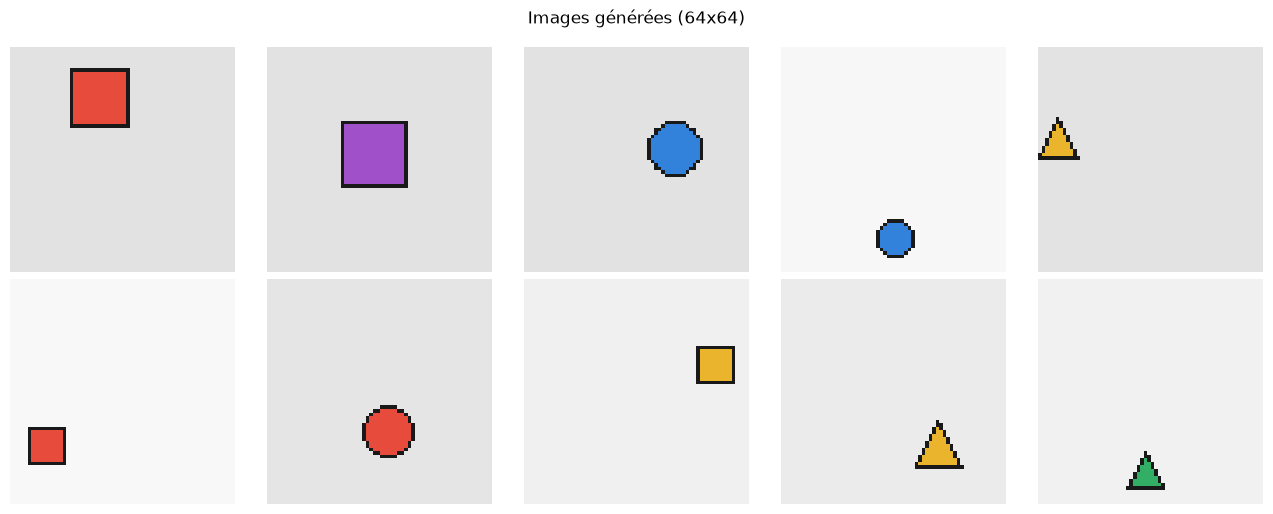

In [2]:
rng = random.Random(123)
pil_images = [make_example(MODEL_SIZE, rng)[0] for _ in range(10)]
show_images(pil_images, f"Images générées ({MODEL_SIZE}x{MODEL_SIZE})")

In [3]:
def to_tensor(image):
    return torch.from_numpy(np.asarray(image.convert("RGB"), dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

images = torch.stack([to_tensor(im) for im in pil_images])
print(images.shape)

def make_dataset(count, seed):
    rng = random.Random(seed)
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(MODEL_SIZE, rng)
        cx, cy, width, height, cls = map(float, label.split())
        dataset_images.append(to_tensor(image))
        targets.append(code(cx, cy, width, height, int(cls), size=MODEL_SIZE))
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))

torch.Size([10, 3, 64, 64])


In [4]:
import time

TRAIN_SAMPLES = 2000
VAL_SAMPLES = 500
BATCH_SIZE = 64
EPOCHS = 50

def run(channels=(8, 16, 32), seed=0, epochs=EPOCHS, lr=3e-3, verbose=True):
    torch.manual_seed(seed)
    train_loader = DataLoader(make_dataset(TRAIN_SAMPLES, seed=7), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(make_dataset(VAL_SAMPLES, seed=8), batch_size=BATCH_SIZE)
    model = Detector(channels)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history, t0 = [], time.time()
    for epoch in range(1, epochs + 1):
        loss = train(model, train_loader, optimizer)
        val_iou, val_iou50, val_acc, conf = evaluate(model, val_loader, MODEL_SIZE)
        history.append((loss, val_iou, val_iou50, val_acc))
        if verbose:
            print(f"epoch {epoch:2d}  loss {loss:.4f}  val IoU {val_iou:.3f}  "
                  f"IoU>0.5 {val_iou50:.0%}  acc classe {val_acc:.0%}")
    n_params = sum(p.numel() for p in model.parameters())
    print(f"channels={channels}  params={n_params}  temps={time.time()-t0:.0f}s")
    return model, history, conf

model, history, conf = run(channels=(8, 16, 32))

epoch  1  loss 1.7925  val IoU 0.414  IoU>0.5 27%  acc classe 53%
epoch  2  loss 0.8853  val IoU 0.550  IoU>0.5 62%  acc classe 79%
epoch  3  loss 0.5026  val IoU 0.604  IoU>0.5 75%  acc classe 93%
epoch  4  loss 0.3153  val IoU 0.627  IoU>0.5 77%  acc classe 94%
epoch  5  loss 0.2459  val IoU 0.643  IoU>0.5 82%  acc classe 97%
epoch  6  loss 0.2000  val IoU 0.672  IoU>0.5 87%  acc classe 99%
epoch  7  loss 0.1714  val IoU 0.681  IoU>0.5 88%  acc classe 98%
epoch  8  loss 0.1501  val IoU 0.681  IoU>0.5 88%  acc classe 99%
epoch  9  loss 0.1420  val IoU 0.696  IoU>0.5 89%  acc classe 99%
epoch 10  loss 0.1323  val IoU 0.684  IoU>0.5 87%  acc classe 99%
epoch 11  loss 0.1261  val IoU 0.700  IoU>0.5 90%  acc classe 99%
epoch 12  loss 0.1152  val IoU 0.717  IoU>0.5 93%  acc classe 100%
epoch 13  loss 0.1073  val IoU 0.694  IoU>0.5 87%  acc classe 99%
epoch 14  loss 0.1081  val IoU 0.715  IoU>0.5 92%  acc classe 100%
epoch 15  loss 0.1074  val IoU 0.707  IoU>0.5 89%  acc classe 99%
epoch 16

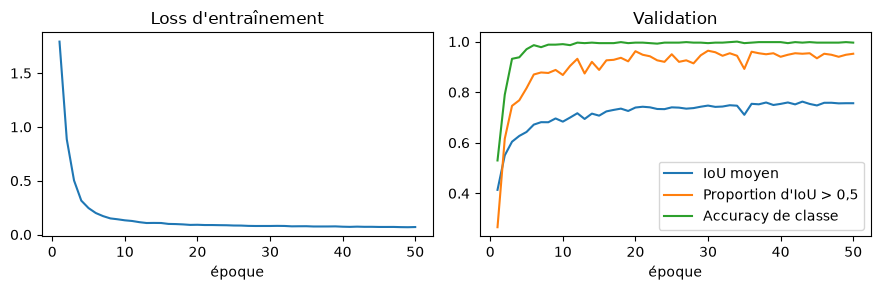

In [8]:
import matplotlib.pyplot as plt

ep = range(1, len(history) + 1)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))

ax[0].plot(ep, [h[0] for h in history])
ax[0].set_title("Loss d'entraînement")
ax[0].set_xlabel("époque")

ax[1].plot(ep, [h[1] for h in history], label="IoU moyen")
ax[1].plot(ep, [h[2] for h in history], label="Proportion d'IoU > 0,5")
ax[1].plot(ep, [h[3] for h in history], label="Accuracy de classe")
ax[1].set_title("Validation")
ax[1].set_xlabel("époque")
ax[1].legend()

plt.tight_layout()
plt.show()

tensor([[152,   0,   0],
        [  2, 174,   0],
        [  0,   0, 172]])


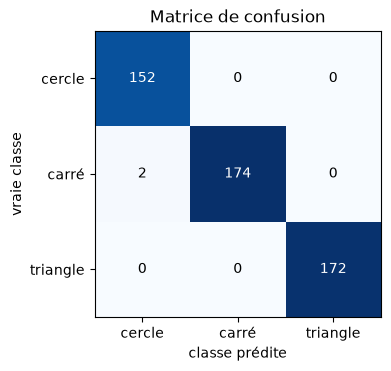

In [5]:
print(conf)
show_confusion(conf, CLASS_NAMES)

torch.Size([10, 32, 8, 8])


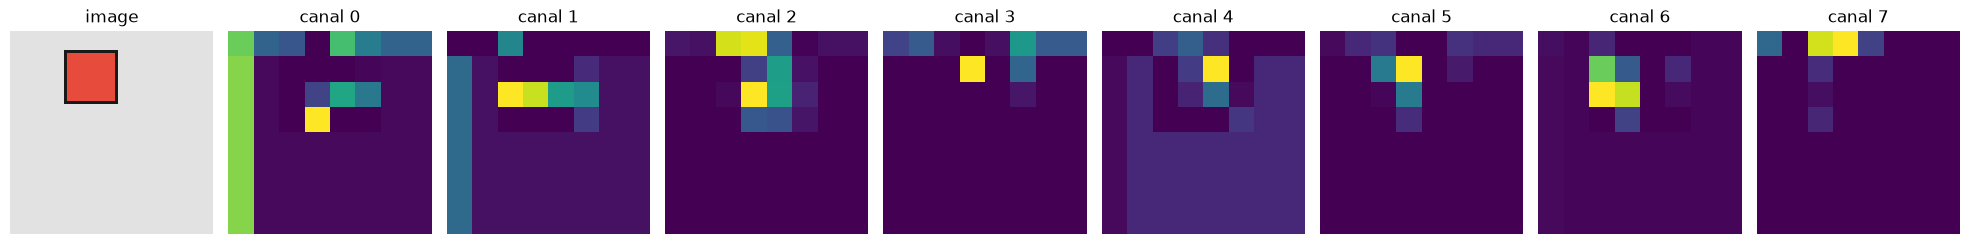

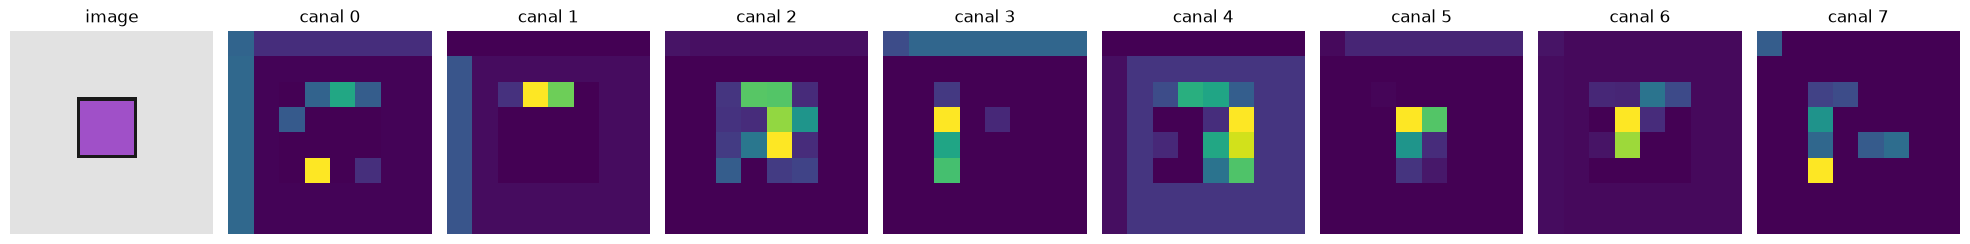

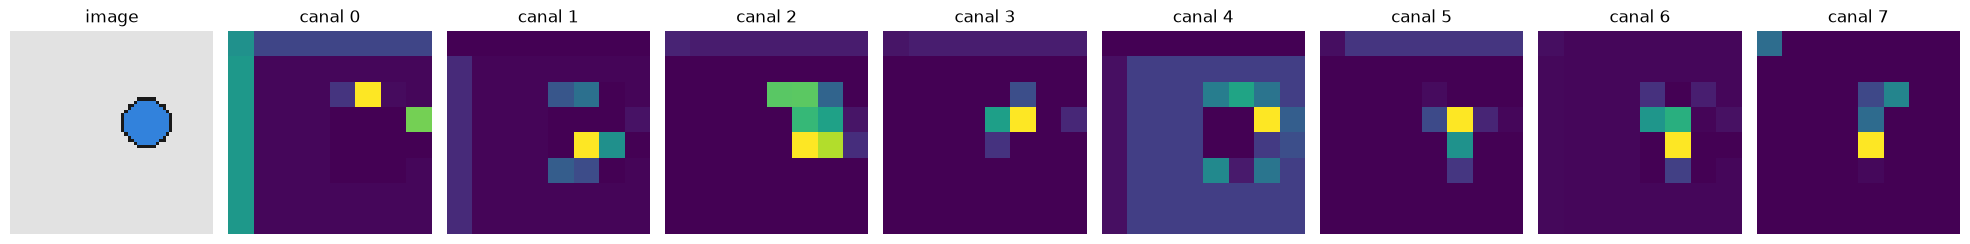

In [6]:
model.eval()
with torch.no_grad():
    maps = model.feature_maps(images)
print(maps.shape)
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)

torch.Size([10, 8, 8, 8])


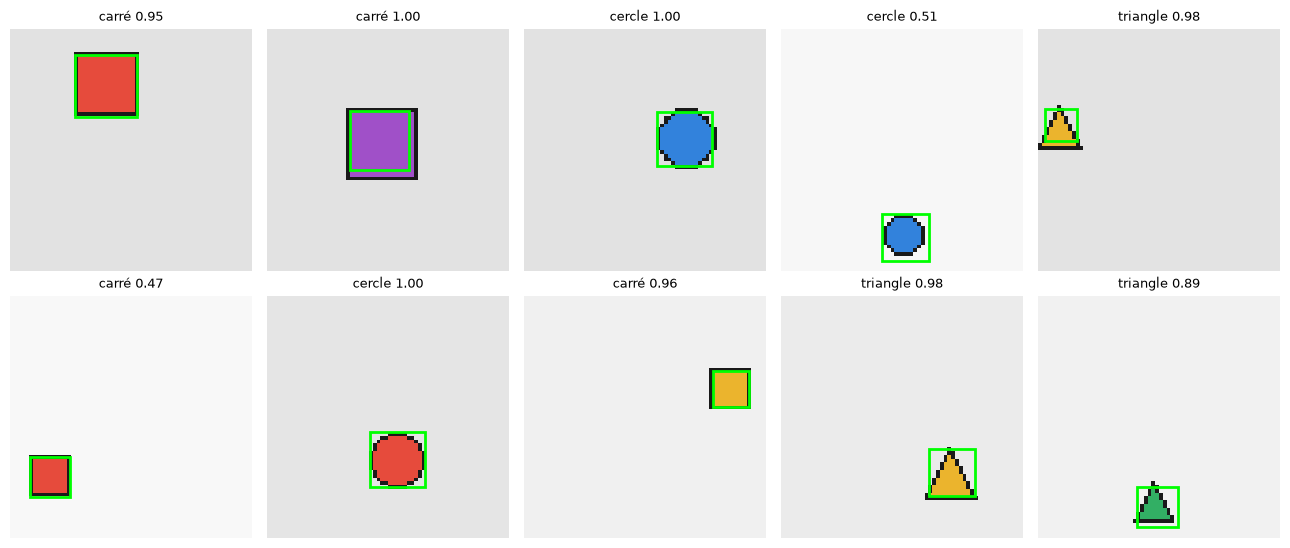

In [7]:
with torch.no_grad():
    logits = model(images)
print(logits.shape)
results = [predict(l, MODEL_SIZE) for l in logits]
show_detections(list(images),
                [b for b, _, _ in results],
                [s for _, s, _ in results],
                labels=[CLASS_NAMES[c] for _, _, c in results])

In [9]:
model2, history2, conf2 = run(channels=(16, 32, 64))
print(conf2)
print("accuracy de classe :", conf2.diag().sum().item() / conf2.sum().item())

epoch  1  loss 1.4923  val IoU 0.375  IoU>0.5 21%  acc classe 68%
epoch  2  loss 0.4975  val IoU 0.568  IoU>0.5 65%  acc classe 93%
epoch  3  loss 0.2455  val IoU 0.648  IoU>0.5 82%  acc classe 99%
epoch  4  loss 0.1754  val IoU 0.665  IoU>0.5 85%  acc classe 99%
epoch  5  loss 0.1435  val IoU 0.685  IoU>0.5 89%  acc classe 98%
epoch  6  loss 0.1290  val IoU 0.680  IoU>0.5 88%  acc classe 100%
epoch  7  loss 0.1182  val IoU 0.694  IoU>0.5 90%  acc classe 99%
epoch  8  loss 0.1098  val IoU 0.692  IoU>0.5 88%  acc classe 100%
epoch  9  loss 0.1031  val IoU 0.709  IoU>0.5 90%  acc classe 99%
epoch 10  loss 0.1031  val IoU 0.323  IoU>0.5 24%  acc classe 60%
epoch 11  loss 0.1103  val IoU 0.712  IoU>0.5 92%  acc classe 100%
epoch 12  loss 0.0959  val IoU 0.729  IoU>0.5 93%  acc classe 100%
epoch 13  loss 0.0888  val IoU 0.735  IoU>0.5 93%  acc classe 99%
epoch 14  loss 0.0850  val IoU 0.729  IoU>0.5 93%  acc classe 100%
epoch 15  loss 0.0813  val IoU 0.739  IoU>0.5 93%  acc classe 100%
epoc